# DeepWeeds — Data Splits & Augmentation



In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

sys.path.insert(0, str(Path("../src").resolve()))
from data import load_folds, IMG_DIR

IMG_DIR = Path(IMG_DIR)
print("Python / PyTorch ready:", torch.__version__)
print("Image directory:", IMG_DIR)
assert IMG_DIR.exists(), f"Image directory not found: {IMG_DIR}"


Python / PyTorch ready: 2.14.1+cpu
Image directory: C:\Users\USER\Documents\Academics\Y4S1\CS3244\github\CS3244-DeepWeeds\data\images


## 1. Load and inspect existing split assignments

In [2]:
df = load_folds()
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())
print("\nHeld-out test indicator:")
print(df["is_test"].value_counts(dropna=False))

for col in ["fold_random", "fold_grouped"]:
    print(f"\n{col} (non-test images):")
    print(df.loc[~df["is_test"], col].value_counts(dropna=False).sort_index())


Rows: 17509
Columns: ['Filename', 'Label', 'Species', 'date', 'instrument', 'session', 'is_test', 'fold_random', 'fold_grouped']


,Filename,Label,Species,date,instrument,session,is_test,fold_random,fold_grouped
0,20160928-140314-0.jpg,0,Chinee apple,20160928,0,20160928-0,True,-1,-1
1,20160928-140337-0.jpg,0,Chinee apple,20160928,0,20160928-0,True,-1,-1
2,20160928-140731-0.jpg,0,Chinee apple,20160928,0,20160928-0,True,-1,-1
3,20160928-140747-0.jpg,0,Chinee apple,20160928,0,20160928-0,True,-1,-1
4,20160928-141107-0.jpg,0,Chinee apple,20160928,0,20160928-0,True,-1,-1



Held-out test indicator:
is_test
False    13274
True      4235
Name: count, dtype: int64

fold_random (non-test images):
fold_random
0    2655
1    2655
2    2655
3    2655
4    2654
Name: count, dtype: int64

fold_grouped (non-test images):
fold_grouped
0    2454
1    2748
2    2721
3    2717
4    2634
Name: count, dtype: int64


## 2. Select a training and validation fold

In [3]:
VAL_FOLD = 0
non_test = df.loc[~df["is_test"]].copy()

train_df = non_test.loc[non_test["fold_random"] != VAL_FOLD].copy()
val_df = non_test.loc[non_test["fold_random"] == VAL_FOLD].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
assert len(train_df) > 0 and len(val_df) > 0


Training images: 10619
Validation images: 2655


## 3. Verify splits and inspect training imbalance

Shared sessions in grouped split: 0


,Training images
Species,
Negative,5615
Parkinsonia,825
Rubber vine,736
Lantana,692
Parthenium,660
Snake weed,544
Prickly acacia,534
Siam weed,524
Chinee apple,489


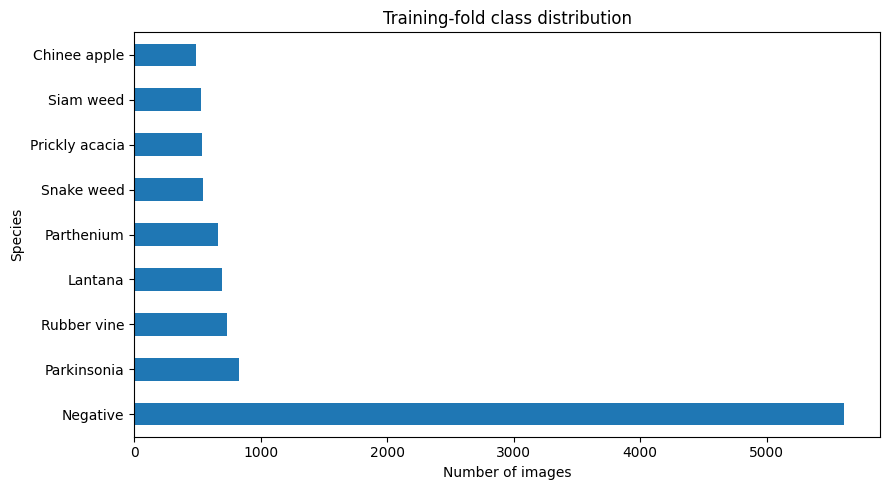

In [4]:
# Basic filename- and held-out-test leakage checks
assert set(train_df["Filename"]).isdisjoint(set(val_df["Filename"]))
assert not train_df["is_test"].any() and not val_df["is_test"].any()

# The grouped folds are separated by collection conditions and can be used for the final evaluation. 
# The separate grouped folds should keep collection sessions together.
group_train = non_test.loc[non_test["fold_grouped"] != VAL_FOLD]
group_val = non_test.loc[non_test["fold_grouped"] == VAL_FOLD]
shared_sessions = set(group_train["session"]) & set(group_val["session"])
print("Shared sessions in grouped split:", len(shared_sessions))
assert not shared_sessions, "Grouped split has shared sessions"

train_class_counts = train_df["Species"].value_counts()
display(train_class_counts.to_frame("Training images"))
ax = train_class_counts.plot.barh(figsize=(9, 5), title="Training-fold class distribution")
ax.set_xlabel("Number of images")
plt.tight_layout()
plt.show()

## 4. Define transforms (training only)

Use square-preserving rotations at 0°, 90°, 180° or 270° and stronger brightness jitter. Validation uses only deterministic resizing and cropping. CutMix will be implemented separately at training time.

In [5]:
import random
from torchvision.transforms import functional as TF

class RandomRotate90:
    """Rotate a square image by a random multiple of 90 degrees."""
    def __call__(self, img):
        return TF.rotate(img, random.choice([0, 90, 180, 270]))

# resize -> random crop -> random rotation -> random flip -> color jitter -> to tensor -> normalize
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    RandomRotate90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=(0.4, 1.3), # brightness varies from 40% darker to 30% brighter
        contrast=0.2, # contrast varies from 20% darker to 20% brighter
        saturation=0.2, # saturation varies from 20% less to 20% more
        hue=0.05, # hue varies from -5% to +5%
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop(224), # validation metric under a consistent crop 
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

## 5. Define datasets

In [6]:
class DeepWeedsDataset(Dataset):
    def __init__(self, dataframe, img_dir, transform, classes):
        self.df = dataframe.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform
        self.classes = list(classes)
        self.class_to_idx = {name: i for i, name in enumerate(self.classes)}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with Image.open(self.img_dir / row["Filename"]) as img:
            image = img.convert("RGB")
        label = self.class_to_idx[row["Species"]]
        if self.transform is not None:
            image = self.transform(image)
        return image, label

# Explicit, shared mapping for training and validation
classes = sorted(df["Species"].unique())
train_dataset = DeepWeedsDataset(train_df, IMG_DIR, train_transform, classes)
val_dataset = DeepWeedsDataset(val_df, IMG_DIR, val_transform, classes)
print("Classes:", classes)
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Classes: ['Chinee apple', 'Lantana', 'Negative', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed']
Training samples: 10619
Validation samples: 2655


## 6. Class-balanced sampling and DataLoaders

In [7]:
# each image is assigned a weight inversely proportional to its class frequency in the training fold
sample_weights = (1.0 / train_df["Species"].map(train_class_counts)).to_numpy()
sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True,
)

train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=0)


## 7. Sanity-check a batch

In [8]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Unique labels in batch:", torch.unique(labels))

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Unique labels in batch: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8])


## 8. Visualize random augmentation

Check that rotated and darker variations do not hide identifying features.

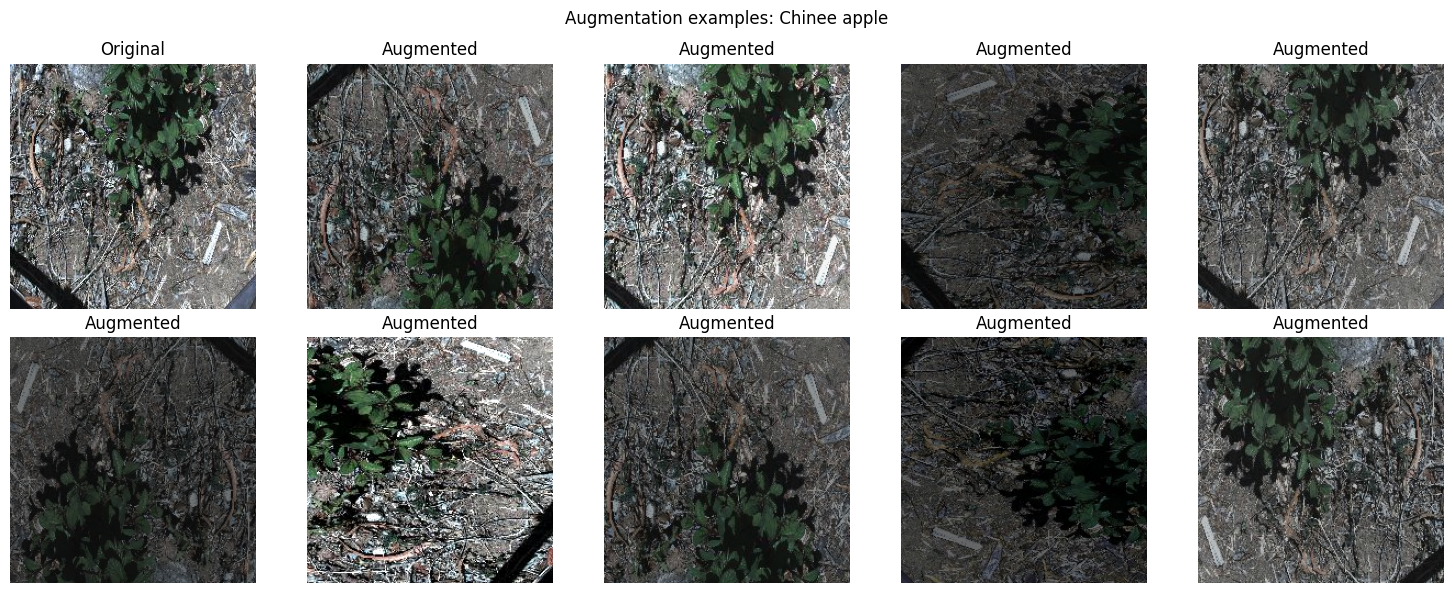

In [9]:
# Show the original and nine independently augmented versions.
sample_row = train_df.iloc[0]
with Image.open(IMG_DIR / sample_row["Filename"]) as img:
    original = img.convert("RGB")

denormalize = transforms.Normalize(
    mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
    std=[1 / 0.229, 1 / 0.224, 1 / 0.225],
)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    if i == 0:
        ax.imshow(original)
        ax.set_title("Original")
    else:
        tensor = denormalize(train_transform(original))
        ax.imshow(tensor.permute(1, 2, 0).clamp(0, 1))
        ax.set_title("Augmented")
    ax.axis("off")
plt.suptitle(f"Augmentation examples: {sample_row['Species']}")
plt.tight_layout()
plt.show()

## 9. Verify weighted sampling

Draw one epoch of sampler indices and compare the sampled labels against the original training-fold labels. Sampling balances expected exposure, **not** the number of unique images on disk.

,Original training images,Sampled in one epoch
Species,,
Chinee apple,489,1240
Lantana,692,1169
Negative,5615,1168
Parkinsonia,825,1213
Parthenium,660,1176
Prickly acacia,534,1130
Rubber vine,736,1184
Siam weed,524,1160
Snake weed,544,1179


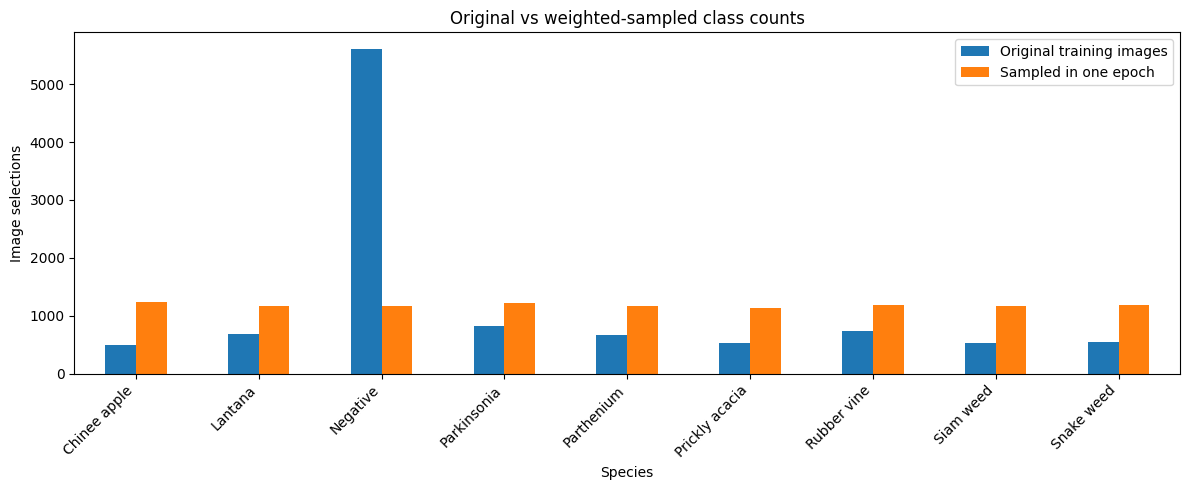

In [10]:
sampled_indices = list(iter(sampler))
sampled_species = train_dataset.df.iloc[sampled_indices]["Species"]

comparison = pd.DataFrame({
    "Original training images": train_class_counts,
    "Sampled in one epoch": sampled_species.value_counts(),
}).fillna(0).astype(int)
display(comparison)

ax = comparison.plot.bar(figsize=(12, 5), title="Original vs weighted-sampled class counts")
ax.set_xlabel("Species")
ax.set_ylabel("Image selections")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 10. Define CutMix (batch-level augmentation)

CutMix operates on **training batches** after the DataLoader supplies them. Use this only during training, never for validation or test images. This section checks the augmentation independently of any model or optimizer. It teaches the model to recognize features from different classes within a single image.

In [11]:
from torchvision.transforms import v2

cutmix = v2.CutMix(num_classes=len(classes), alpha=1.0)

def apply_cutmix(images, labels, probability=0.5):
    if torch.rand(()).item() < probability:
        return cutmix(images, labels)
    return images, labels


## 11. Verify CutMix outputs

For this test, `probability=1.0` ensures CutMix runs. It should preserve image shape and return one probability vector per class for every image.

In [12]:
# Test one batch only — no training/model/optimizer needed.
images, labels = next(iter(train_loader))
mixed_images, mixed_labels = apply_cutmix(images, labels, probability=1.0)

print("Original image shape:", tuple(images.shape))
print("Mixed image shape:", tuple(mixed_images.shape))
print("Original label shape:", tuple(labels.shape))
print("Mixed label shape:", tuple(mixed_labels.shape))
print("First 5 probability sums:", mixed_labels.sum(dim=1)[:5])

assert mixed_images.shape == images.shape
assert mixed_labels.shape == (len(labels), len(classes))
assert torch.allclose(mixed_labels.sum(dim=1), torch.ones(len(labels)), atol=1e-5)
assert torch.all(mixed_labels >= 0) and torch.all(mixed_labels <= 1)
print("CutMix verification successful!")


Original image shape: (32, 3, 224, 224)
Mixed image shape: (32, 3, 224, 224)
Original label shape: (32,)
Mixed label shape: (32, 9)
First 5 probability sums: tensor([1., 1., 1., 1., 1.])
CutMix verification successful!


## 12. Visualize original versus CutMix images

CutMix replaces a rectangle in each image with a patch from another image in the batch. Some pairs may share the same class, so the two leading label names can sometimes coincide or a mixing weight can be zero.

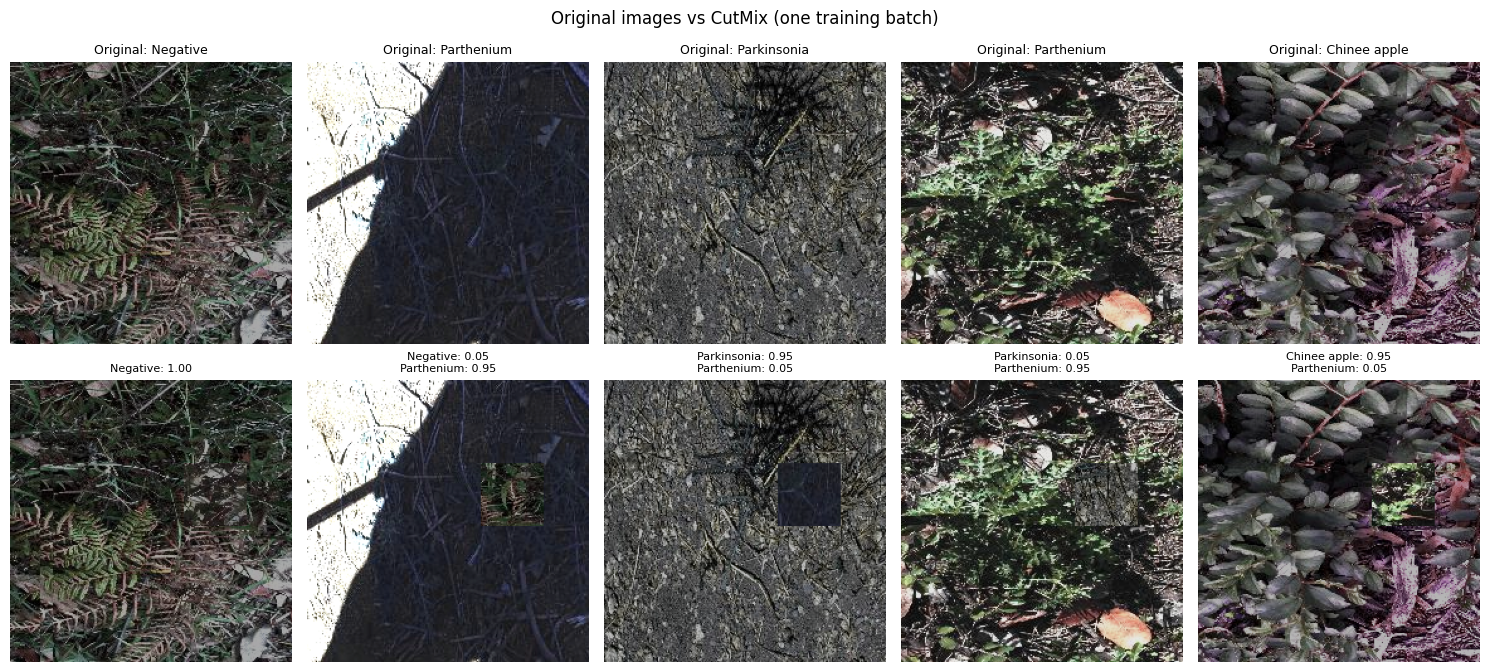

In [13]:
# Reuse the verified batch from the previous cell.
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def show_rgb(tensor):
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

n_show = min(5, len(labels))
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 7), squeeze=False)
for i in range(n_show):
    axes[0, i].imshow(show_rgb(images[i]))
    axes[0, i].set_title(f"Original: {classes[labels[i].item()]}", fontsize=9)
    axes[0, i].axis("off")

    axes[1, i].imshow(show_rgb(mixed_images[i]))
    nonzero = torch.nonzero(mixed_labels[i] > 1e-6).flatten().tolist()
    label_text = "\n".join(
        f"{classes[j]}: {mixed_labels[i, j].item():.2f}" for j in nonzero
    )
    axes[1, i].set_title(label_text, fontsize=8)
    axes[1, i].axis("off")

plt.suptitle("Original images vs CutMix (one training batch)")
plt.tight_layout()
plt.show()
